In [ ]:
!git clone https://github.com/eg4000/SKU110K_CVPR19.git

Cloning into 'SKU110K_CVPR19'...
remote: Enumerating objects: 538, done.
remote: Counting objects: 100% (88/88), done.
remote: Compressing objects: 100% (19/19), done.
remote: Total 538 (delta 78), reused 69 (delta 69), pack-reused 450 (from 1)
Receiving objects: 100% (538/538), 18.25 MiB | 16.42 MiB/s, done.
Resolving deltas: 100% (253/253), done.


In [ ]:
import os

print(os.listdir("SKU110K_CVPR19"))

['README.md', 'figures', 'Pipfile', 'Poster.pdf', 'Supplementary_Material__Precise_Detection_in_Densely_Packed_Scenes.pdf', 'object_detector_retinanet', '.git', 'snapshots', '.gitignore', 'requirements.txt', 'Pipfile.lock', 'Object Recognition in retail - AI week 2019 presentation.pdf']


In [ ]:
!pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.4/46.4 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 54.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 75.8/75.8 kB 4.7 MB/s eta 0:00:00


In [ ]:
from ultralytics.data.utils import check_det_dataset

dataset = check_det_dataset("SKU-110K.yaml", autodownload=True)

print(dataset)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.

WARNING ⚠️ Dataset 'SKU-110K.yaml' images not found, missing path '/content/datasets/SKU-110K/val.txt'
Unzipping /content/datasets/SKU110K_fixed.tar.gz to /content/datasets...
Converting /content/datasets/SKU-110K/annotations_train.csv: 100% ━━━━━━━━━━━━ 8219/8219 31.0it/s 4:25
Converting /content/datasets/SKU-110K/annotations_val.csv: 100% ━━━━━━━━━━━━ 588/588 175.4it/s 3.4s
Converting /content/datasets/SKU-110K/annotations_test.csv: 100% ━━━━━━━━━━━━ 2936/2936 78.2it/s 37.6s
Dataset download success ✅ (1175.2s), saved to /content/datasets

{'path': PosixPath('/content/datasets/SKU-110K'), 'train': '/content/datasets/SKU-110K/train.txt', 'val': '/content/datasets/SKU-110K/val.txt', 'test': '/cont

In [ ]:
import os

dataset_path = "/content/datasets/SKU-110K"

print("Dataset contents:")
print(os.listdir(dataset_path))

Dataset contents:
['labels', 'images', 'val.txt', 'train.txt', 'LICENSE.txt', 'annotations', 'test.txt']


In [ ]:
import os

dataset_path = "/content/datasets/SKU-110K"

for root, dirs, files in os.walk(dataset_path):
    level = root.replace(dataset_path, "").count(os.sep)

    if level <= 2:
        print("  " * level + os.path.basename(root) + "/")

        for file in files[:10]:
            print("  " * (level + 1) + file)

SKU-110K/
  val.txt
  train.txt
  LICENSE.txt
  test.txt
  labels/
    train_3746.txt
    train_4954.txt
    val_554.txt
    train_2435.txt
    train_5563.txt
    train_5190.txt
    train_6068.txt
    train_6755.txt
    test_167.txt
    test_720.txt
  images/
    train_3607.jpg
    train_968.jpg
    test_2871.jpg
    train_5005.jpg
    train_4007.jpg
    test_2327.jpg
    train_6250.jpg
    train_2959.jpg
    train_5470.jpg
    train_3879.jpg
  annotations/
    annotations_test.csv
    annotations_val.csv
    readme.txt
    annotations_train.csv


In [ ]:
import os

labels_path = "/content/datasets/SKU-110K/labels"

# Pick the first label file
label_file = os.listdir(labels_path)[0]
label_path = os.path.join(labels_path, label_file)

print("Label file:", label_file)
print("\nContents:\n")

with open(label_path, "r") as f:
    print(f.read())

Label file: train_3746.txt

Contents:

0 0.72324 0.46691 0.01920 0.04596
0 0.69506 0.47411 0.02900 0.04259
0 0.61479 0.46369 0.06209 0.07261
0 0.66605 0.44148 0.02655 0.01900
0 0.71078 0.42877 0.01961 0.02604
0 0.43137 0.46232 0.04739 0.06863
0 0.66687 0.47518 0.02574 0.04167
0 0.74694 0.46691 0.02328 0.04596
0 0.93546 0.51256 0.10948 0.06005
0 0.27921 0.02880 0.07149 0.05699
0 0.95037 0.42586 0.10253 0.04596
0 0.86601 0.47626 0.03023 0.04075
0 0.83885 0.47442 0.02002 0.04259
0 0.79636 0.47381 0.02492 0.04075
0 0.38807 0.46140 0.03023 0.06801
0 0.59518 0.55193 0.07271 0.06648
0 0.02492 0.02528 0.03758 0.04994
0 0.77083 0.47534 0.02124 0.03952
0 0.19792 0.54718 0.04616 0.06863
0 0.34906 0.46063 0.04861 0.06710
0 0.97590 0.34314 0.04984 0.09620
0 0.26103 0.45496 0.05964 0.08517
0 0.52002 0.55132 0.07190 0.06342
0 0.44506 0.54887 0.07475 0.06710
0 0.37092 0.54979 0.06699 0.05974
0 0.31230 0.54733 0.05025 0.05974
0 0.25347 0.54979 0.06005 0.06219
0 0.33578 0.37025 0.03758 0.04994
0 0.38011

In [ ]:
import os

labels_path = "/content/datasets/SKU-110K/labels"

label_file = os.listdir(labels_path)[0]
label_path = os.path.join(labels_path, label_file)

print("Label file:", label_file)
print("\nFirst 10 annotations:\n")

with open(label_path, "r") as f:
    for i, line in enumerate(f):
        print(line.strip())
        if i == 9:
            break

Label file: train_3746.txt

First 10 annotations:

0 0.72324 0.46691 0.01920 0.04596
0 0.69506 0.47411 0.02900 0.04259
0 0.61479 0.46369 0.06209 0.07261
0 0.66605 0.44148 0.02655 0.01900
0 0.71078 0.42877 0.01961 0.02604
0 0.43137 0.46232 0.04739 0.06863
0 0.66687 0.47518 0.02574 0.04167
0 0.74694 0.46691 0.02328 0.04596
0 0.93546 0.51256 0.10948 0.06005
0 0.27921 0.02880 0.07149 0.05699


Image size: (3264, 2448)
Label file: train_6898.txt


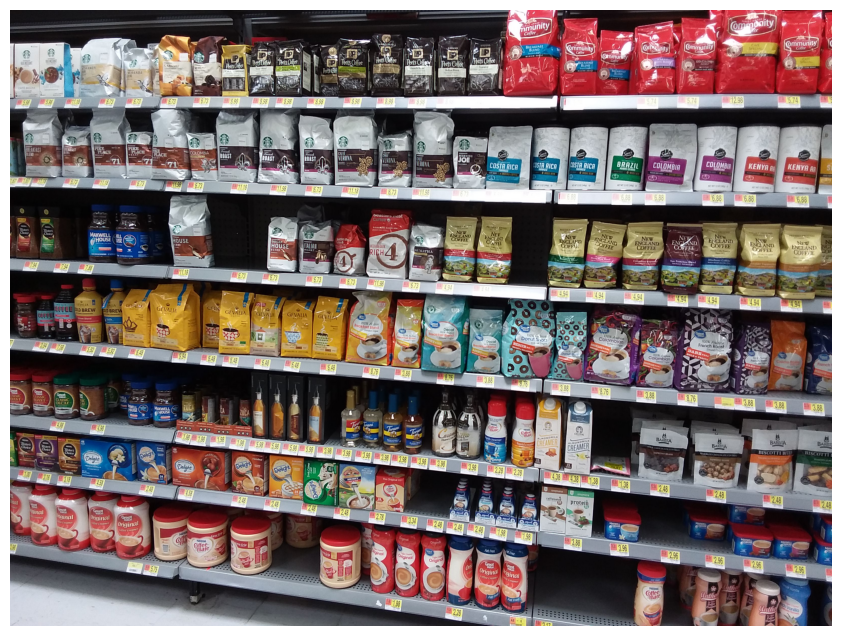

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt
import os

dataset_path = "/content/datasets/SKU-110K"

# Use the label file we just inspected
label_file = "train_6898.txt"

# Corresponding image
image_file = "train_6898.jpg"

image_path = os.path.join(dataset_path, "images", image_file)
label_path = os.path.join(dataset_path, "labels", label_file)

# Load image
image = Image.open(image_path)

print("Image size:", image.size)
print("Label file:", label_file)

# Display image
plt.figure(figsize=(12, 8))
plt.imshow(image)
plt.axis("off")
plt.show()

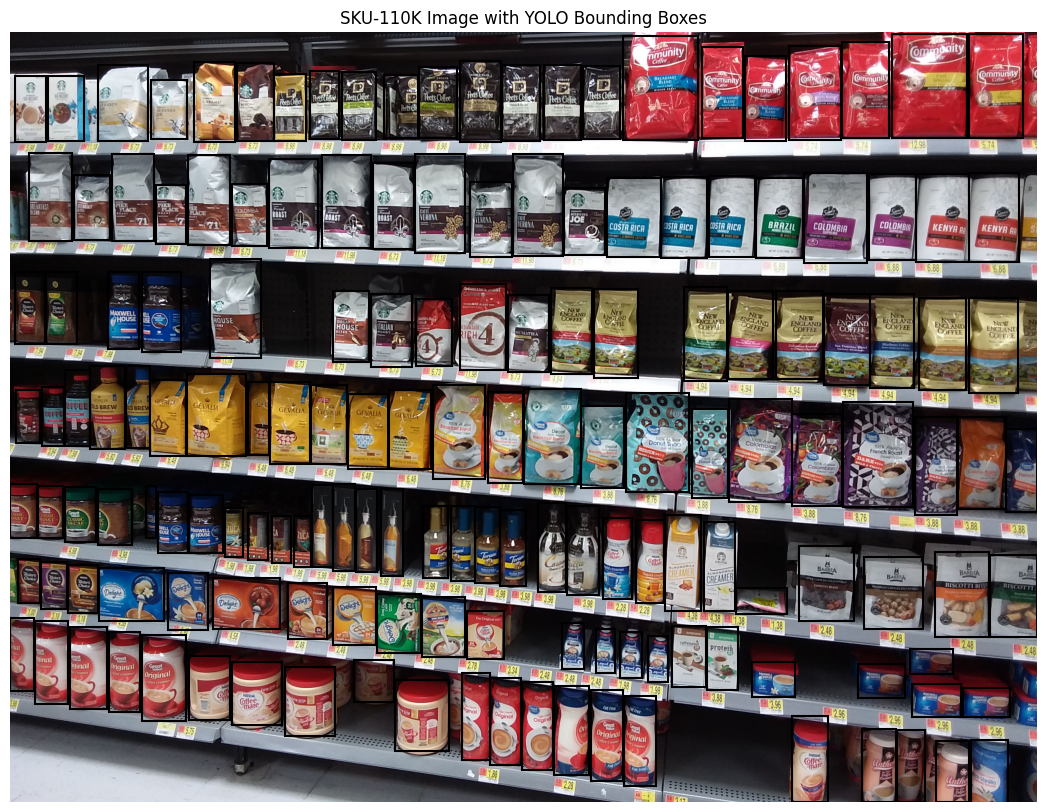

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import os

dataset_path = "/content/datasets/SKU-110K"

image_file = "train_6898.jpg"
label_file = "train_6898.txt"

image_path = os.path.join(dataset_path, "images", image_file)
label_path = os.path.join(dataset_path, "labels", label_file)

# Load image
image = Image.open(image_path)
img_width, img_height = image.size

# Create figure
fig, ax = plt.subplots(figsize=(15, 10))
ax.imshow(image)

# Read YOLO annotations
with open(label_path, "r") as f:
    for line in f:
        values = line.strip().split()

        if len(values) != 5:
            continue

        class_id, x_center, y_center, width, height = map(float, values)

        # Convert normalized YOLO coordinates to pixels
        x_center *= img_width
        y_center *= img_height
        width *= img_width
        height *= img_height

        # Convert center coordinates to top-left coordinates
        x = x_center - width / 2
        y = y_center - height / 2

        # Draw bounding box
        box = patches.Rectangle(
            (x, y),
            width,
            height,
            linewidth=1.5,
            fill=False
        )

        ax.add_patch(box)

ax.set_title("SKU-110K Image with YOLO Bounding Boxes")
ax.axis("off")
plt.show()

In [ ]:
!pip install -q ultralytics

In [ ]:
from ultralytics import YOLO
import os

print("YOLO ready!")

YOLO ready!


In [ ]:
yaml_content = """
path: /content/datasets/SKU-110K

train: train.txt
val: val.txt
test: test.txt

names:
  0: object
"""

with open("/content/sku110k.yaml", "w") as f:
    f.write(yaml_content)

print("Dataset configuration created!")

Dataset configuration created!


In [ ]:
model = YOLO("yolov8n.pt")

print("Pretrained YOLOv8n loaded!")

Pretrained YOLOv8n loaded!


In [ ]:
results = model.train(
    data="/content/sku110k.yaml",
    epochs=30,
    imgsz=640,
    batch=16,
    device=0,
    workers=2,
    project="/content/drive/MyDrive/SKU110K_results",
    name="yolov8n_baseline",
    save_period=1
)

Ultralytics 8.4.147 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/sku110k.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8n_baseline, nbs=64, nms=None, opset=None, optimi

In [ ]:
!find "/content/drive/MyDrive/SKU110K_results" -type f \( -name "best.pt" -o -name "last.pt" \)

/content/drive/MyDrive/SKU110K_results/yolov8n_baseline/weights/best.pt
/content/drive/MyDrive/SKU110K_results/yolov8n_baseline/weights/last.pt
